# Buscando la $f_c$ del filtro ambiente nuevo

Queremos un filtro con $f_c$ baja, pero que deje medir una curva IV completa (los dos lados,
hasta ±80 µA) en unos 30 s. La fuente de corriente (6220) tiene el LO a tierra, y eso pesa mucho:
los capacitores del filtro ambiente van a tierra, y parte de la corriente se escapa por ellos antes
de llegar a la juntura. Cada punto tarda más en estabilizarse.

Comparo dos formas de medir la curva, con el filtro de siempre (capacitores a tierra):

1. pasos de 10 nA en toda la curva (rampa uniforme);
2. menos puntos: pasos finos solo donde hacen falta (rampa corta).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy import linalg, optimize

# curva y tiempos
I_MAX = 80e-6           # A, hasta donde llega la curva (y -I_MAX del otro lado)
FINO, GRUESO = 10e-9, 1e-6
PASO_SUBGAP = 1e-9      # A, paso en la zona subgap: el ajuste de R_sg (1,8–2,2 mV) son solo ~6,5 nA
T_OBJETIVO = 30.0       # s por curva completa
T_EQUIPO = 10e-3        # s por punto que necesita el equipo (lo de la tesis; a confirmar)
EPS = 0.01              # el punto se mide cuando el error en la juntura es < 1 % del paso fino

# juntura (8 µm, tesis) y filtro criogénico actual
I_SW, V_GAP, R_N, R_SG, C_J = 24e-6, 2.8e-3, 74.0, 62e3, 50e-12
R_CRY, C_CRY = 22.0, 47e-9
LO_A_TIERRA = True
R_MAX = 1000.0          # no uso R más grandes: más ruido térmico y casi no mejora

K = np.sqrt((np.sqrt(53) - 7) / 2)   # 0,374, de f_c = K / (2 pi R' C') para dos etapas RC

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"

## El circuito

Las cuatro líneas (corriente y voltímetro), el filtro ambiente, el criogénico y la juntura, resuelto
con Kirchhoff nodo por nodo. El filtro ambiente puede tener capacitores a tierra (`C_tierra`), entre
las líneas de cada par (`C_entre`), o los dos.

Para cada punto de la rampa calculo cuánto hay que esperar para que la corriente en la juntura
esté a menos del 1 % del paso fino de su valor final, sumando lo que dejan los escalones anteriores.

In [2]:
def armar(R, C_tierra, C_entre, R_J, lo_a_tierra=LO_A_TIERRA):
    nodos, Rs, Cs = {}, [], []
    n = lambda x: -1 if x == "G" else nodos.setdefault(x, len(nodos))
    r = lambda a, b, v: Rs.append((n(a), n(b), v))
    c = lambda a, b, v: Cs.append((n(a), n(b), v))
    for a, b in (("p", "m"), ("sp", "sm")):            # par de corriente y par del voltímetro
        for ln in (a, b):
            r(f"{ln}0", f"{ln}1", R); r(f"{ln}1", f"{ln}2", R)
            if C_tierra: c(f"{ln}1", "G", C_tierra); c(f"{ln}2", "G", C_tierra)
            r(f"{ln}2", f"{ln}3", R_CRY); r(f"{ln}3", f"{ln}4", R_CRY)
        if C_entre: c(f"{a}1", f"{b}1", C_entre); c(f"{a}2", f"{b}2", C_entre)
        c(f"{a}3", f"{b}3", C_CRY); c(f"{a}4", f"{b}4", C_CRY)
    r("p4", "Jp", R_CRY); r("m4", "Jm", R_CRY); r("sp4", "Jp", R_CRY); r("sm4", "Jm", R_CRY)
    r("sp0", "sm0", 1e9); r("sp0", "G", 2e10); r("sm0", "G", 2e10)   # nanovoltímetro
    r("Jp", "Jm", R_J); c("Jp", "Jm", C_J)                           # juntura
    if lo_a_tierra: r("m0", "G", 1e-3)
    else: r("p0", "G", 2e10); r("m0", "G", 2e10)
    N = len(nodos); G = np.zeros((N, N)); Cm = np.eye(N) * 1e-12
    for M, lista, f in ((G, Rs, lambda x: 1 / x), (Cm, Cs, lambda x: x)):
        for i, j, x in lista:
            M[i, i] += f(x)
            if j >= 0: M[j, j] += f(x); M[i, j] -= f(x); M[j, i] -= f(x)
    b = np.zeros(N); b[nodos["p0"]], b[nodos["m0"]] = 1, -1
    out = np.zeros(N); out[nodos["Jp"]], out[nodos["Jm"]] = 1 / R_J, -1 / R_J
    A, B = -linalg.solve(Cm, G), linalg.solve(Cm, b)
    w, V = linalg.eig(A)
    coef = -(out @ V) * linalg.solve(V, B) / w
    coef = coef / np.real(coef.sum())
    ok = (np.abs(coef) > 1e-5) & (np.real(w) < -1e-2)
    return w[ok], coef[ok]


def t_punto(modos, eps):
    w, c = modos
    tau = -1 / np.real(w).max()
    def err(T):
        k = np.arange(1, int(np.ceil(40 * tau / T)) + 6)
        return abs(np.real((c * np.exp(np.outer(k * T, w))).sum()))
    return 10**optimize.brentq(lambda x: np.log(max(err(10**x), 1e-300)) - np.log(eps),
                               np.log10(tau) - 4, np.log10(tau) + 4)


def fc(R, C_tierra, C_entre):
    '''f_c del modo diferencial (el ruido que le llega a la juntura).'''
    return K / (2 * np.pi * 2 * R * (C_tierra / 2 + C_entre))

# chequeo: el filtro de 1801 Hz con la fuente flotante tiene que dar 1,45 ms por punto
# (el valor ya verificado contra LTspice y la simulación temporal en el otro notebook)
print(f"{t_punto(armar(15, 2.2e-6, 0, 1e-3, lo_a_tierra=False), EPS)*1e3:.2f} ms")

1.45 ms


## Las dos rampas

En la curva la juntura pasa por tres estados, y cada uno carga distinto al filtro: voltaje cero (un
corto), rama normal ($R_N$ = 74 Ω) y la zona subgap ($R_{sg}$ = 62 kΩ), que es la lenta.

- Rampa uniforme: 10 nA en toda la curva.
- Rampa corta: 10 nA solo alrededor del salto (22–26 µA) y al final de la bajada (0,5 µA → 0);
  1 µA en el resto.

En las dos, la zona subgap va con pasos de 1 nA. R_sg se ajusta entre 1,8 y 2,2 mV, que con
62 kΩ son solo 29–35,5 nA: con pasos de 10 nA caerían 0 o 1 puntos ahí; con 1 nA caen ~6–7.

En los puntos de paso grueso pido el mismo error absoluto (0,1 nA), o sea más tiempo de espera.

In [3]:
I_SG = V_GAP / R_SG
def rampa(corta):
    g = GRUESO if corta else FINO
    tramos = [(-1e-6, 22e-6, g, "cero"), (22e-6, I_SW, FINO, "cero"), (I_SW, 26e-6, FINO, "normal"),
              (26e-6, I_MAX, g, "normal"), (I_MAX, 0.5e-6, g, "normal"), (0.5e-6, I_SG, FINO, "normal"),
              (I_SG, 0, PASO_SUBGAP, "subgap"), (0, -1e-6, g, "cero")]
    n = {}
    for a, b, p, z in tramos:
        clave = (z, p)
        n[clave] = n.get(clave, 0) + 2 * max(1, round(abs(b - a) / p))   # x2: lado positivo y negativo
    return n

RAMPAS = {"uniforme": rampa(False), "corta": rampa(True)}
for k, v in RAMPAS.items():
    print(f"rampa {k}: {sum(v.values())} puntos -> con {T_EQUIPO*1e3:g} ms/punto, "
          f"{sum(v.values())*T_EQUIPO:.0f} s solo por el equipo")

rampa uniforme: 32480 puntos -> con 10 ms/punto, 325 s solo por el equipo
rampa corta: 1296 puntos -> con 10 ms/punto, 13 s solo por el equipo


Con 10 nA en toda la curva son ~32 000 puntos: aunque el filtro fuera instantáneo, con 10 ms por
punto la curva tarda más de 5 minutos. Con la rampa corta son ~1300, y el equipo solo ya entra en
los 15 s.

## Barrido

Para cada combinación comercial de $R$ (serie E6, 10 Ω a 1 kΩ) y $C$ (10 nF a 2,2 µF) calculo el tiempo
por punto en cada estado, y con eso el tiempo de la curva completa para cada rampa. Lo hago para
los dos diseños. Tarda unos minutos.

In [4]:
E6 = [10, 15, 22, 33, 47, 68]
R_LISTA = [r * m for m in (1, 10, 100) for r in E6] + [1000]
C_LISTA = [c * 1e-9 for c in E6 + [100, 150, 220, 330, 470, 680, 1000, 1500, 2200]]
R_ESTADO = {"cero": 1e-3, "normal": R_N, "subgap": R_SG}

def t_curva(tp, n_rampa, t_equipo=T_EQUIPO):
    return sum(n * max(tp[(z, FINO * EPS / p)], t_equipo) for (z, p), n in n_rampa.items())

filas = []
for Cc in C_LISTA:
    for R in R_LISTA:
        tp = {}
        for (z, p) in set().union(*RAMPAS.values()):
            eps = FINO * EPS / p
            if (z, eps) not in tp:
                tp[(z, eps)] = t_punto(armar(R, Cc, 0, R_ESTADO[z]), eps)
        fila = dict(R=R, C=Cc, fc=fc(R, Cc, 0))
        for k, n in RAMPAS.items():
            fila[f"t_{k}"] = t_curva(tp, n)          # con el equipo
            fila[f"t_{k}_filtro"] = t_curva(tp, n, 0) # solo el filtro
        filas.append(fila)
df = pd.DataFrame(filas)
print(len(df), "combinaciones")

285 combinaciones


## Idea 1: pasos de 10 nA en toda la curva

Cada punto es una combinación de $R$ y $C$; el color es el valor de $C$ (barra de la derecha).
Los cuadrados rojos son los 6 filtros actuales.

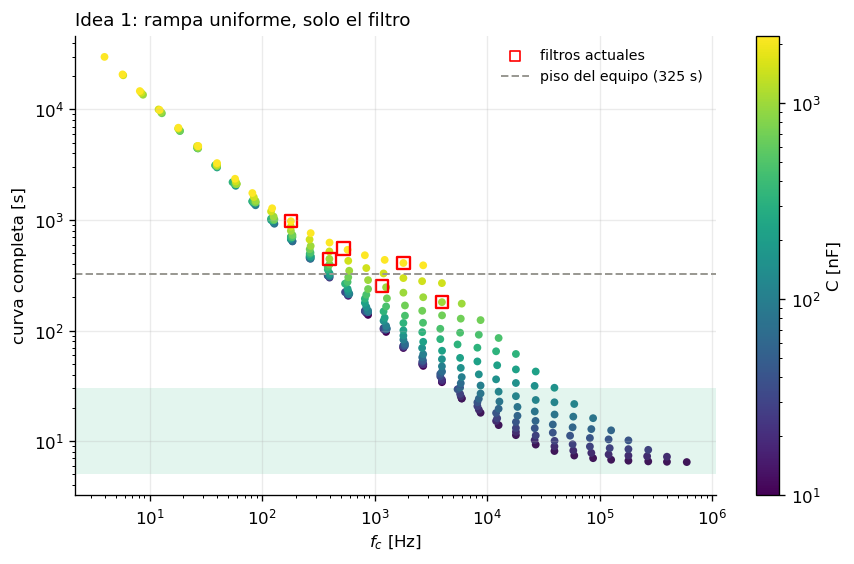

In [5]:
def mapa(ax, d, col_t, titulo):
    sc = ax.scatter(d.fc, d[col_t], c=d.C * 1e9, norm=LogNorm(), cmap="viridis", s=22, lw=0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.axhspan(5, T_OBJETIVO, color=VERDE, alpha=0.12, lw=0)
    ax.set_xlabel("$f_c$ [Hz]")
    ax.set_ylabel("curva completa [s]")
    ax.set_title(titulo, loc="left", fontsize=11)
    return sc

def filtros_actuales(ax, col):
    '''Los 6 filtros actuales como cuadrados rojos (51 Ω no está en la grilla, los calculo aparte).'''
    rampa_k = col.replace("t_", "").replace("_filtro", "")
    t_eq = 0 if col.endswith("_filtro") else T_EQUIPO
    for R, Cc in actuales:
        tp = {(z, FINO * EPS / p): t_punto(armar(R, Cc, 0, R_ESTADO[z]), FINO * EPS / p)
              for (z, p) in RAMPAS[rampa_k]}
        ax.scatter(fc(R, Cc, 0), t_curva(tp, RAMPAS[rampa_k], t_eq), marker="s", s=55,
                   facecolors="none", edgecolors="red", lw=1.4)
    ax.scatter([], [], marker="s", facecolors="none", edgecolors="red", label="filtros actuales")

actuales = [(150, 2.2e-6), (150, 1e-6), (51, 2.2e-6), (51, 1e-6), (15, 2.2e-6), (15, 1e-6)]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
sc = mapa(ax, df, "t_uniforme_filtro", "Idea 1: rampa uniforme, solo el filtro")
filtros_actuales(ax, "t_uniforme_filtro")
ax.axhline(sum(RAMPAS["uniforme"].values()) * T_EQUIPO, color=GRIS, ls="--", lw=1.2,
           label=f"piso del equipo ({sum(RAMPAS['uniforme'].values())*T_EQUIPO:.0f} s)")
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
plt.colorbar(sc, ax=ax, label="C [nF]"); plt.tight_layout(); plt.show()

Solo con el filtro (sin contar el equipo), para entrar en la franja verde hace falta una $f_c$ de
varios kHz, y los filtros actuales tardan minutos. Además, con más de 32 000 puntos, el equipo solo
ya pone un piso de más de 5 minutos. Por este camino no se llega.

## Idea 2: rampa corta

Ahora sí con el tiempo real: en cada punto se espera lo que sea más largo, el filtro o el equipo.

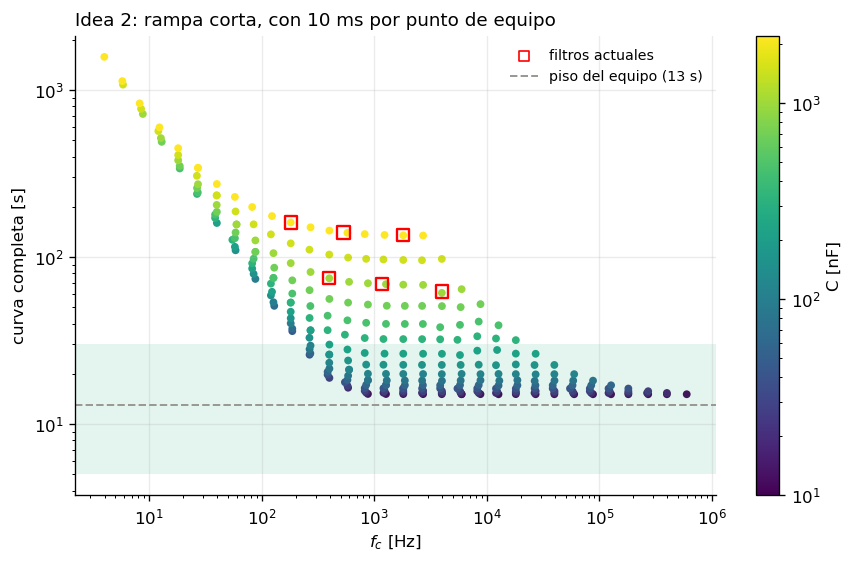

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
piso = sum(RAMPAS["corta"].values()) * T_EQUIPO
sc = mapa(ax, df, "t_corta", f"Idea 2: rampa corta, con {T_EQUIPO*1e3:g} ms por punto de equipo")
filtros_actuales(ax, "t_corta")
ax.axhline(piso, color=GRIS, ls="--", lw=1.2, label=f"piso del equipo ({piso:.0f} s)")
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
plt.colorbar(sc, ax=ax, label="C [nF]"); plt.tight_layout(); plt.show()

Con la rampa corta, muchos filtros quedan cerca del piso del equipo (~13 s): ahí el filtro ya no
es lo que limita, y conviene elegir el que más filtra entre esos.

## Las dos ideas juntas

Para cada idea, la mejor $f_c$ que se puede tener para cada tiempo de curva (el borde de abajo de
cada nube de puntos). La estrella es la elección.

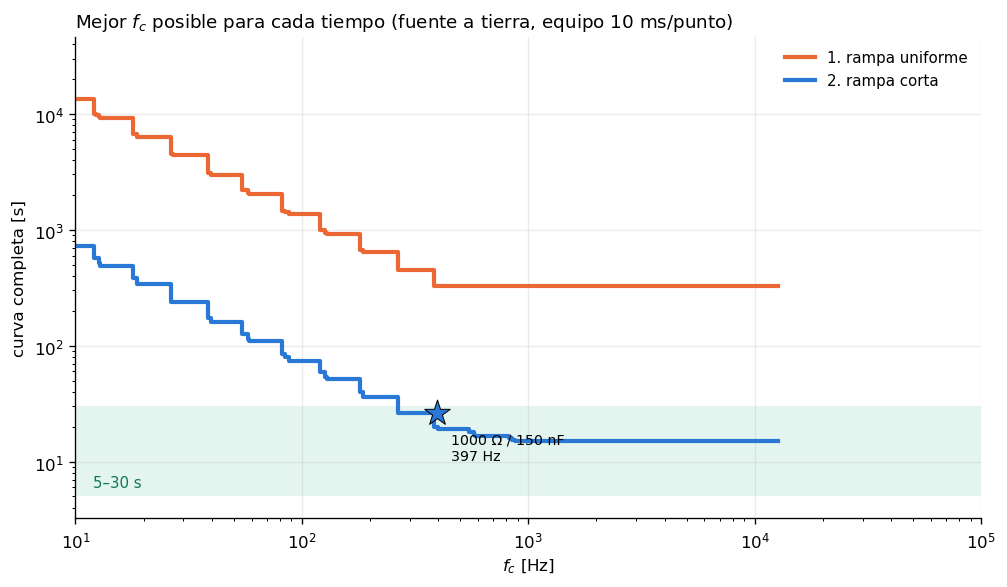

In [7]:
def borde(d, col_t):
    '''Para cada tiempo, la f_c más baja posible (combinaciones no superadas en f_c y en tiempo).'''
    d = d.sort_values("fc"); fr, mejor = [], np.inf
    for f, t in zip(d.fc, d[col_t]):
        if t < mejor: fr.append((f, t)); mejor = t
    return np.array(fr)

ideas = [("1. rampa uniforme", "t_uniforme", NARANJA),
         ("2. rampa corta", "t_corta", AZUL)]
PRINCIPAL = "2. rampa corta"   # la elección (ver conclusión)

def elegir(col_t, t_obj=T_OBJETIVO):
    ok = df[(df[col_t] <= t_obj) & (df.R <= R_MAX)]
    return None if ok.empty else ok.sort_values(["fc", col_t]).iloc[0]

fig, ax = plt.subplots(figsize=(8.5, 5))
for nombre, col, color in ideas:
    fr = borde(df, col)
    ax.step(fr[:, 0], fr[:, 1], where="post", color=color, lw=2.5, label=nombre)
    e = elegir(col)
    if e is not None and nombre == PRINCIPAL:
        ax.scatter(e.fc, e[col], marker="*", s=260, color=color, edgecolor="k", lw=0.6, zorder=5)
        ax.annotate(f"{e.R:g} Ω / {e.C*1e9:g} nF\n{e.fc:.0f} Hz", (e.fc, e[col]),
                    xytext=(8, -28), textcoords="offset points", fontsize=8.5)
ax.axhspan(5, T_OBJETIVO, color=VERDE, alpha=0.12, lw=0)
ax.text(12, 6, f"5–{T_OBJETIVO:g} s", color="#0d7a52", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(10, 1e5)
ax.set_xlabel("$f_c$ [Hz]"); ax.set_ylabel("curva completa [s]")
ax.set_title(f"Mejor $f_c$ posible para cada tiempo (fuente a tierra, equipo {T_EQUIPO*1e3:g} ms/punto)",
             loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper right"); plt.tight_layout(); plt.show()

In [8]:
filas = []
for nombre, col, _ in ideas:
    for t_obj in (15, 30, 60):
        e = elegir(col, t_obj)
        filas.append({"idea": nombre, "curva ≤ [s]": t_obj,
                      "filtro": "no entra" if e is None else f"{e.R:g} Ω / {e.C*1e9:g} nF",
                      "f_c [Hz]": "" if e is None else round(e.fc),
                      "curva [s]": "" if e is None else round(e[col], 1)})
print(pd.DataFrame(filas).to_string(index=False))

             idea  curva ≤ [s]          filtro f_c [Hz] curva [s]
1. rampa uniforme           15        no entra                   
1. rampa uniforme           30        no entra                   
1. rampa uniforme           60        no entra                   
   2. rampa corta           15        no entra                   
   2. rampa corta           30 1000 Ω / 150 nF      397      26.1
   2. rampa corta           60 1000 Ω / 330 nF      180      53.5


## Fuente flotante vs a tierra

Tiempo de la curva completa (equipo 10 ms/punto) con la fuente flotante y con el LO a tierra, para
los 6 filtros actuales y los dos propuestos.

In [9]:
FILTROS_TABLA = [(f"{R:g} Ω / {Cc*1e6:g} µF", R, Cc) for R, Cc in actuales] + [
    ("1 kΩ / 150 nF (propuesto)", 1000, 150e-9),
    ("1 kΩ / 100 nF (más rápido)", 1000, 100e-9)]
claves = set().union(*RAMPAS.values())

filas, cocientes = [], []
for nombre, R, Cc in FILTROS_TABLA:
    fila = {"filtro": nombre}
    tps = {}
    for lo, txt in ((False, "flotante"), (True, "a tierra")):
        tps[txt] = {(z, FINO * EPS / p): t_punto(armar(R, Cc, 0, R_ESTADO[z], lo_a_tierra=lo), FINO * EPS / p)
                    for (z, p) in claves}
    for k in ("corta", "uniforme"):
        for txt in ("flotante", "a tierra"):
            fila[f"{k}, {txt} [s]"] = round(t_curva(tps[txt], RAMPAS[k]), 1)
    cocientes += [tps["a tierra"][k] / tps["flotante"][k] for k in tps["flotante"]]
    filas.append(fila)
print(pd.DataFrame(filas).to_string(index=False))
print(f"\nPor punto, solo el filtro: la tierra lo hace entre "
      f"{min(cocientes):.1f} y {max(cocientes):.1f} veces más lento.")

                    filtro  corta, flotante [s]  corta, a tierra [s]  uniforme, flotante [s]  uniforme, a tierra [s]
            150 Ω / 2.2 µF                 73.6                161.4                   385.4                   974.6
              150 Ω / 1 µF                 41.4                 74.7                   353.2                   444.8
             51 Ω / 2.2 µF                 73.5                140.7                   385.4                   553.9
               51 Ω / 1 µF                 41.4                 69.1                   353.2                   380.1
             15 Ω / 2.2 µF                 73.5                135.1                   385.4                   444.4
               15 Ω / 1 µF                 41.4                 62.2                   353.2                   374.1
 1 kΩ / 150 nF (propuesto)                 18.6                 26.1                   330.5                   334.7
1 kΩ / 100 nF (más rápido)                 17.3                 

Con los filtros propuestos la diferencia por la tierra es chica (unos pocos segundos) porque el
equipo impone 10 ms por punto: donde el filtro necesita menos que eso, la tierra no se nota. Por
punto, solo el filtro, en voltaje cero la tierra lo hace entre ~4 y ~10 veces más lento con los
filtros actuales (~12 con 1 kΩ / 100 nF); en la subgap, solo ~2 veces, porque ahí manda la
resistencia de la juntura.

## Conclusión

- Elección: 1 kΩ / 150 nF con capacitores a tierra (como el filtro actual) y rampa corta.
  $f_c$ ≈ 400 Hz, y la curva completa tarda ~26 s. Si hace falta más rápido, 1 kΩ / 100 nF
  ($f_c$ ≈ 600 Hz) tarda ~21 s, filtrando menos. En 15 s no entra ningún filtro.
- Capacitores a tierra: según la tesis (§5.2.1), el filtro ambiente está para frenar lo que
  viene de los instrumentos y lo que se acopla en los cables (radio), que es sobre todo modo común,
  y eso lo frenan los capacitores a tierra.
- Lo que más rinde es usar menos puntos: ~1300 en vez de ~32 000. Con 10 nA en toda la curva no
  entra ningún filtro (el equipo solo ya son 325 s).
- La subgap va con pasos de 1 nA, si no no caen puntos en el ajuste de $R_{sg}$. Esos ~90 puntos
  son los más lentos de la curva y su tiempo depende casi solo de la $C$: por eso conviene $C$ chica.
  Con los filtros actuales (1–2,2 µF) la curva tarda entre 1 y 2,5 minutos con la fuente a tierra.

Supuestos: juntura de 8 µm de la tesis; equipo de 10 ms por punto; filtro criogénico actual;
sin la resistencia de los cables del criostato; subgap lineal ($R_{sg}$ constante).

Para ver con Fran: si la rampa corta le sirve; si ~25 s por curva está bien; si el equipo puede
medir a 10 ms por punto; qué paso usa en la subgap.